In [1]:
import sys
import importlib
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append("../src")
import stats
importlib.reload(stats)

os.makedirs("../plots", exist_ok=True)

df = pd.read_parquet("E:/laba_results/clean_final.parquet", columns=["fare_amount"])
x = df["fare_amount"].to_numpy(dtype=np.float64)
del df

print("Записей:", f"{x.size:,}".replace(",", " "))

Записей: 55 418 645


In [2]:
mean_v = x.mean()
median_v = np.median(x)
skew_raw = stats.skewness(x)

x_log = np.log1p(x)
skew_log = stats.skewness(x_log)

print(f"Среднее: {mean_v:.4f}")
print(f"Медиана: {median_v:.4f}")
print(f"Асимметрия, исходная шкала: {skew_raw:.4f}")
print(f"Асимметрия, log1p: {skew_log:.4f}")

Среднее: 11.3414
Медиана: 8.5000
Асимметрия, исходная шкала: 4.2347
Асимметрия, log1p: 0.9795


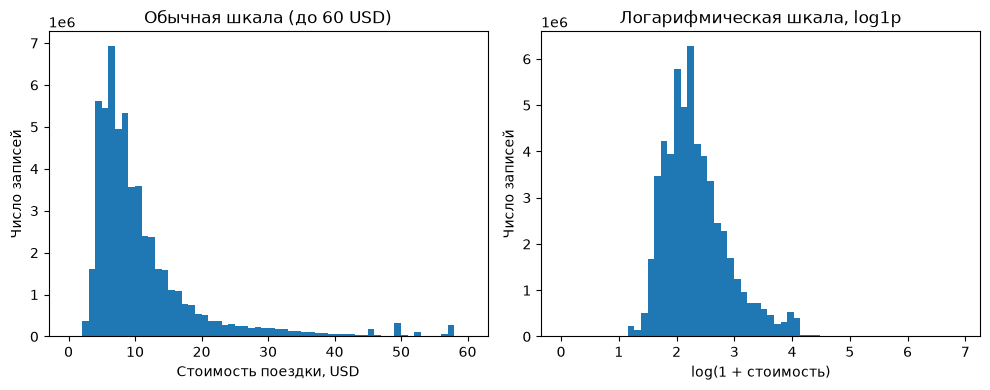

Записей выше 60 USD (не показаны на левой панели): 147 158


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

c1, e1 = np.histogram(x, bins=60, range=(0, 60))
axes[0].stairs(c1, e1, fill=True)
axes[0].set_xlabel("Стоимость поездки, USD")
axes[0].set_ylabel("Число записей")
axes[0].set_title("Обычная шкала (до 60 USD)")

c2, e2 = np.histogram(x_log, bins=60)
axes[1].stairs(c2, e2, fill=True)
axes[1].set_xlabel("log(1 + стоимость)")
axes[1].set_ylabel("Число записей")
axes[1].set_title("Логарифмическая шкала, log1p")

fig.tight_layout()
fig.savefig("../plots/stats_01_hist_scales.png", dpi=150)
plt.show()

print("Записей выше 60 USD (не показаны на левой панели):", f"{int((x > 60).sum()):,}".replace(",", " "))

In [4]:
res = stats.bootstrap_median_ci(x, n_boot=2000, sample_size=50_000, random_state=42)
boot = res["boot"]

print(f"Медиана выборки: {res['median_sample']:.4f}")
print(f"95% бутстрап-интервал: [{res['ci_low']:.4f}; {res['ci_high']:.4f}]")
print(f"Число повторов: {res['n_boot']}")
print("Доля повторов, совпавших с медианой выборки:", round(float(np.mean(boot == res['median_sample'])), 3))

Медиана выборки: 8.5000
95% бутстрап-интервал: [8.5000; 8.5000]
Число повторов: 2000
Доля повторов, совпавших с медианой выборки: 1.0


Гипотеза 1 (Манна–Уитни; из вывода работы 2 о росте стоимости со временем).
H0: распределение стоимости поездки (fare_amount) в 2010 и 2014 годах одинаково.
H1: распределения различаются.
Уровень значимости α = 0,05. Величина, важная для предметной области: разность медиан не менее 0,5 USD.
Размер эффекта: разность медиан (2014 − 2010) с 95 % бутстрап-интервалом и rank-biserial r. Выборка: по 50 000 записей за каждый год, random_state = 42.

Гипотеза 2 (Краскела–Уоллиса, попарные Манна–Уитни с поправкой Холма).
H0: распределение стоимости поездки одинаково во всех группах по числу пассажиров (1–6).
H1: распределения различаются хотя бы для одной пары групп.
Уровень значимости α = 0,05; попарные сравнения с поправкой Холма. Величина, важная для предметной области: разность медиан не менее 0,5 USD.
Размер эффекта: eta² для теста Краскела–Уоллиса; для пар, значимых после поправки, разность медиан с бутстрап-интервалом. Группа 0 и редкие группы (менее 1 % записей) в сравнение не входят.

Гипотеза 3 (z-тест для двух долей).
Событие: изменение тарифов на такси в Нью-Йорке, 1 декабря 2011 г. (дата по данным TLC).
Сравниваемые периоды: до события (с 1 января 2009 по 30 ноября 2011) и после события (с 1 декабря 2011 по 1 июля 2015).
H0: доля поездок стоимостью более 10 USD одинакова до и после события.
H1: доли различаются.
Уровень значимости α = 0,05. Величина, важная для предметной области: разность долей не менее 2 п.п.
Размер эффекта: разность долей в процентных пунктах и h Кохена.